In [ ]:
import json
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    print("Запуск у Google Colab — переконайтесь, що папка 'src/' завантажена у робочу директорію.")

import src
import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


[data_prep] Verified existing stratified split (24997 valid images, seed=42). Reusing clean split.
[data_prep] External unseen test set verified (10 images).
Усього валідних зображень: 24997
Відсіяно пошкоджених файлів: 3
Стандартизовано у RGB JPEG: 255


,Split,Cats (0),Dogs (1),Total,Dog Ratio (%)
0,train,9998,9999,19997,50.0
1,val,1249,1249,2498,50.0
2,test,1251,1251,2502,50.0
3,TOTAL,12498,12499,24997,50.0


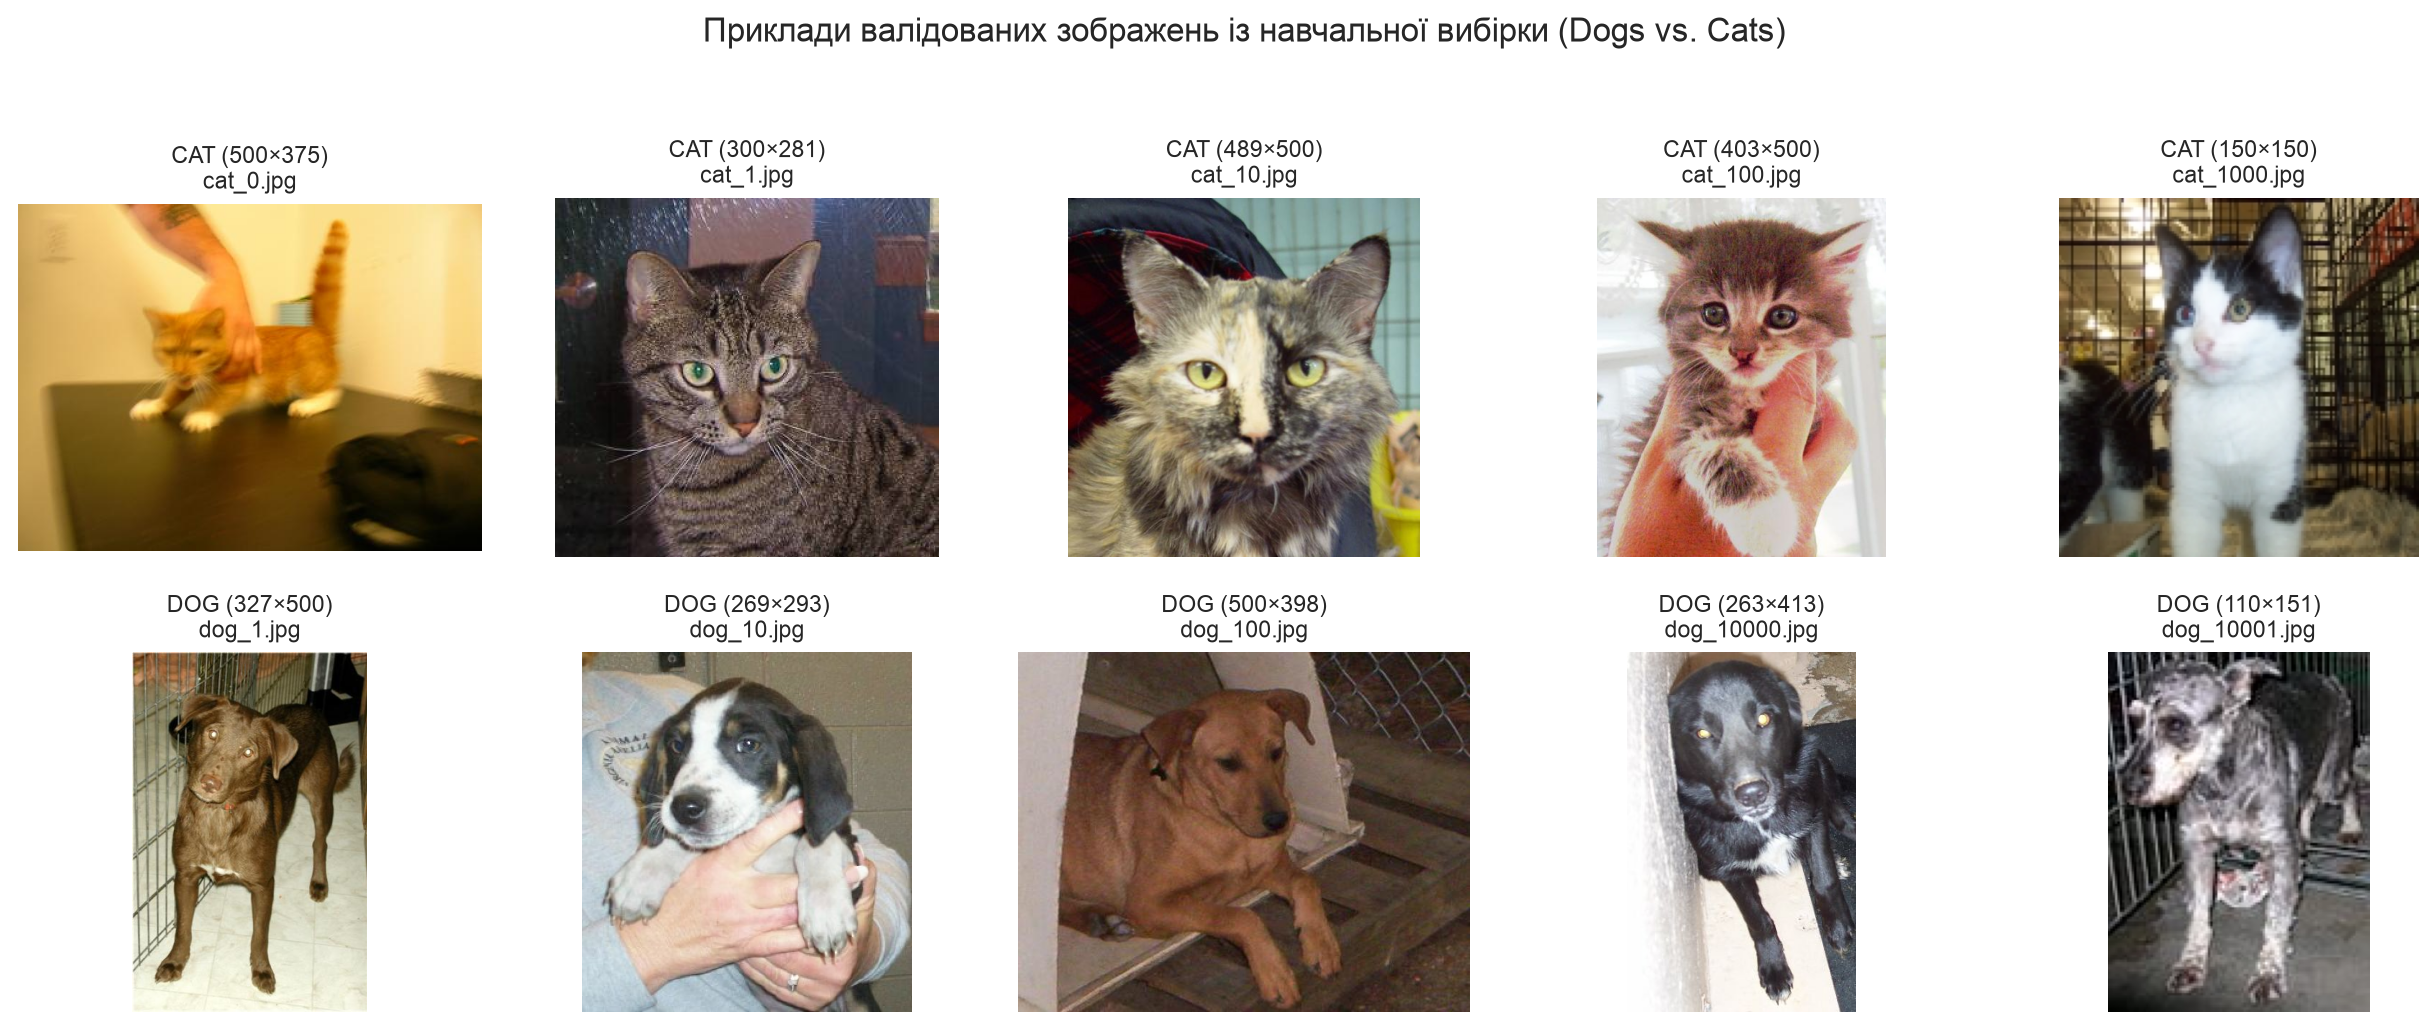

In [2]:
from src.data_prep import prepare_dataset_splits, prepare_external_test_images
from src.dataset import summarize_splits_dataframe
from src.visualization import plot_sample_images

split_stats = prepare_dataset_splits()
external_records = prepare_external_test_images()

print(f"Усього валідних зображень: {split_stats['total_valid']}")
print(f"Відсіяно пошкоджених файлів: {len(split_stats['corrupted_files'])}")
print(f"Стандартизовано у RGB JPEG: {split_stats['reencoded_count']}")

df_splits = summarize_splits_dataframe()
display(df_splits)
plot_sample_images(save_name="00_dataset_samples.png")


In [3]:
from src.config import (
    EX_ADAM_LRS,
    EX_BATCH_SIZES,
    EX_DENSE_UNITS,
    EX_DROPOUT_RATES,
    EX_EPOCH_CHECKPOINTS,
    EX_OPTIMIZERS,
    EX_SECOND_DENSE_UNITS,
    EX_UNFREEZE_BLOCKS,
    MODELS_DIR,
    RESULTS_DIR,
    cleanup_temp_prefix_cache,
)
from src.trainer import (
    extract_or_load_bottleneck_features,
    finalize_and_save_finetuned_model,
    predict_external_images,
    prepare_prefix_cache,
    run_finetuning_experiment,
)
from src.visualization import (
    plot_confusion_matrix,
    plot_external_predictions_grid,
    plot_hyperparameter_bars,
    plot_multi_curves_comparison,
    plot_two_stage_curves,
)

vgg_bottleneck, _ = extract_or_load_bottleneck_features("vgg16")
vgg_prefix_b1 = prepare_prefix_cache("vgg16", unfreeze_blocks=1, train_samples=2000, val_samples=500)

all_study_rows = []


def _append_study_row(group_name: str, param_label: str, rec: dict) -> dict:
    tm = rec["test_metrics"]
    row = {
        "Study Group": group_name,
        "Setting": param_label,
        "Unfrozen Blocks": rec["unfreeze_blocks"],
        "Dense 1": rec["dense_units"],
        "Dense 2": rec["second_dense_units"],
        "Dropout": rec["dropout_rate"],
        "Optimizer": rec["optimizer"].upper(),
        "Learning Rate": rec["learning_rate"],
        "Batch Size": rec["batch_size"],
        "FT Epochs": rec["finetune_epochs"],
        "Best Epoch": rec["best_epoch"],
        "Best Val Loss": rec["best_val_loss"],
        "Overfit Gap (%)": round(rec["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
        "Test Errors": tm["errors_count"],
        "FT Time (s)": rec["finetune_seconds"],
    }
    all_study_rows.append(row)
    return row


[trainer] Loaded Stage-1 bottleneck features for 'vgg16' (dim=512, train=19997).


[trainer] Loaded existing experiment 'vgg16_ex1a_dense_32' -> Test Acc: 98.48% | Loss: 0.0495
[trainer] Loaded existing experiment 'vgg16_ex1a_dense_128' -> Test Acc: 98.44% | Loss: 0.0502
[trainer] Loaded existing experiment 'vgg16_ex1a_dense_256' -> Test Acc: 98.44% | Loss: 0.0567
[trainer] Loaded existing experiment 'vgg16_ex1a_dense_512' -> Test Acc: 98.32% | Loss: 0.0672
[trainer] Loaded existing experiment 'vgg16_ex1a_dense_1024' -> Test Acc: 98.52% | Loss: 0.0605


,Dense Units,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,32,1,0.04770,0.65,98.48,0.0495,0.99843
1,128,4,0.04994,1.45,98.44,0.0502,0.99851
2,256,6,0.05395,1.20,98.44,0.0567,0.99857
3,512,2,0.05918,0.75,98.32,0.0672,0.99853
4,1024,5,0.06756,1.25,98.52,0.0605,0.99877


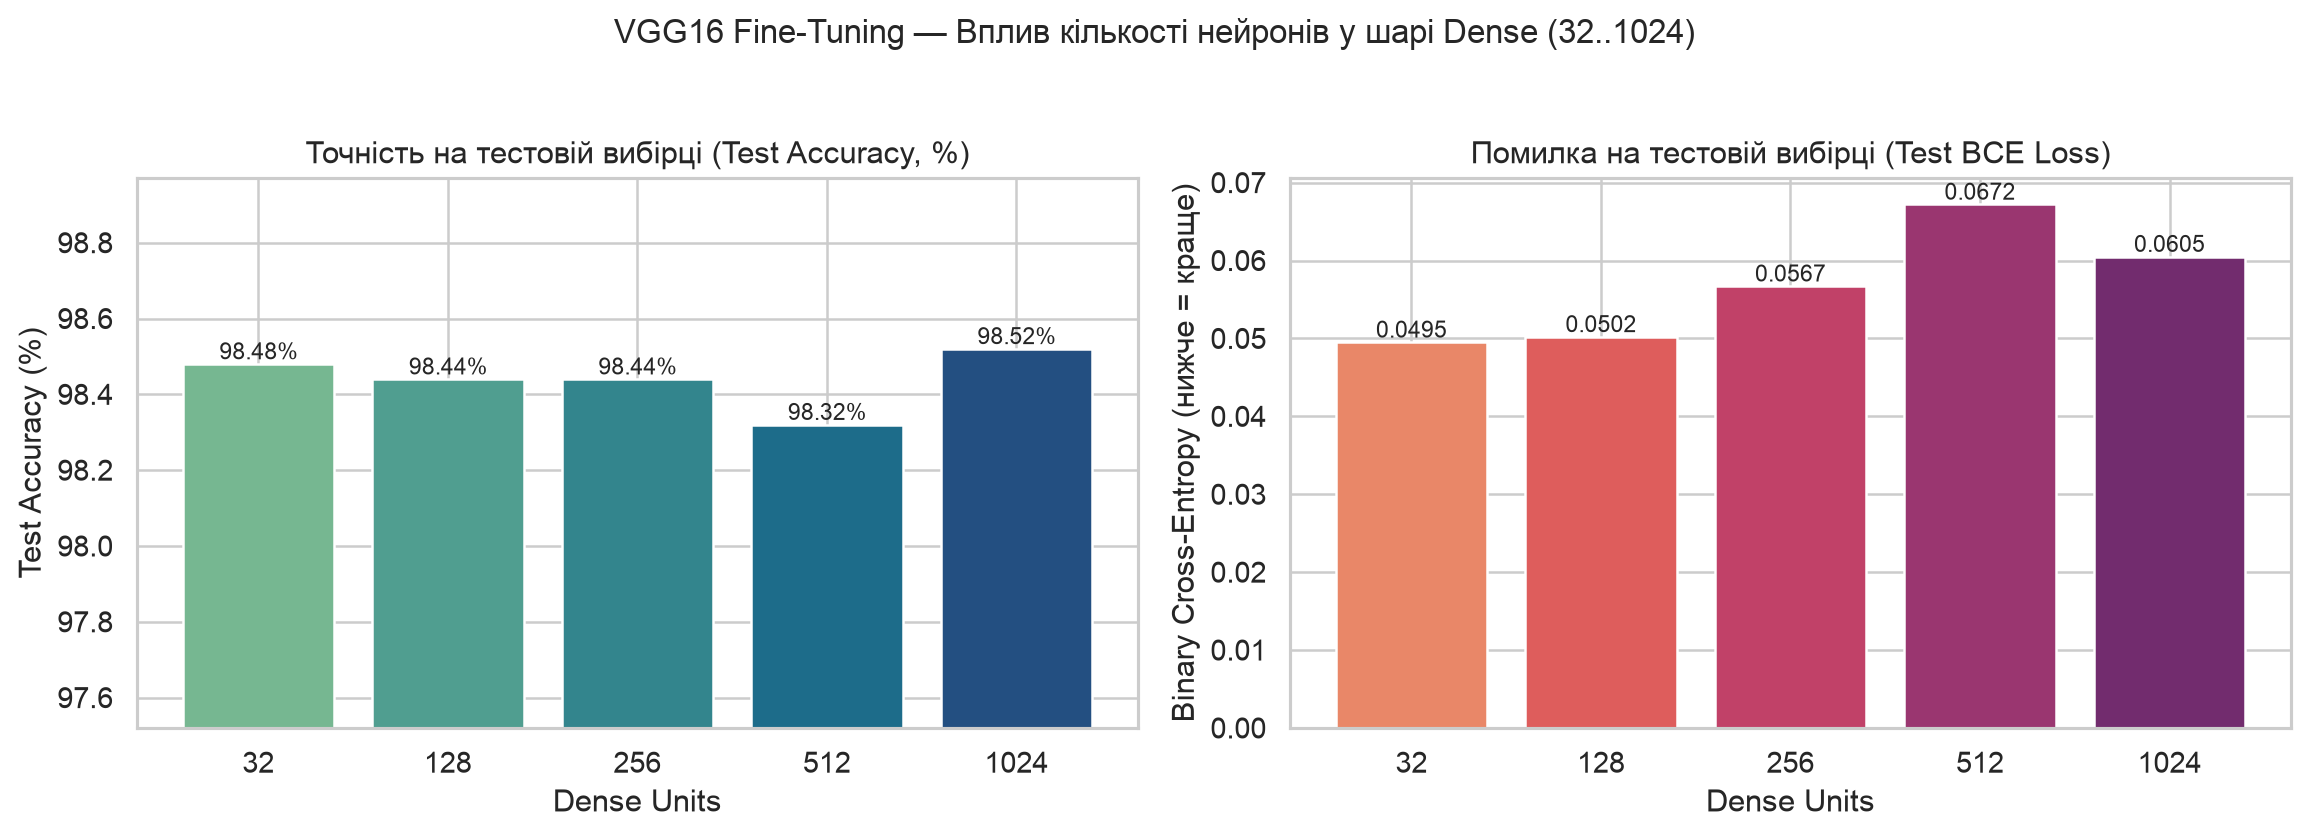

In [4]:
ex1a_rows = []
for units in EX_DENSE_UNITS:
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=units,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"vgg16_ex1a_dense_{units}",
    )
    r = _append_study_row("1a. Dense Units", str(units), rec)
    ex1a_rows.append({"Dense Units": units, **r})

df_ex1a = pd.DataFrame(ex1a_rows)
display(df_ex1a[["Dense Units", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_hyperparameter_bars(
    df_ex1a,
    x_col="Dense Units",
    title="VGG16 Fine-Tuning — Вплив кількості нейронів у шарі Dense (32..1024)",
    save_name="01_vgg16_ex1a_dense_units.png",
)


[trainer] Loaded existing experiment 'vgg16_ex1b_dropout_0_25' -> Test Acc: 98.24% | Loss: 0.0762
[trainer] Loaded existing experiment 'vgg16_ex1b_dropout_0_5' -> Test Acc: 98.44% | Loss: 0.0567
[trainer] Loaded existing experiment 'vgg16_ex1b_dropout_0_6' -> Test Acc: 98.40% | Loss: 0.0482
[trainer] Loaded existing experiment 'vgg16_ex1b_dropout_0_8' -> Test Acc: 98.56% | Loss: 0.0454


,Dropout Rate,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,0.25,8,0.06779,1.20,98.24,0.0762,0.99817
1,0.50,6,0.05395,1.20,98.44,0.0567,0.99857
2,0.60,3,0.04790,1.45,98.40,0.0482,0.99868
3,0.80,3,0.04344,1.15,98.56,0.0454,0.99864


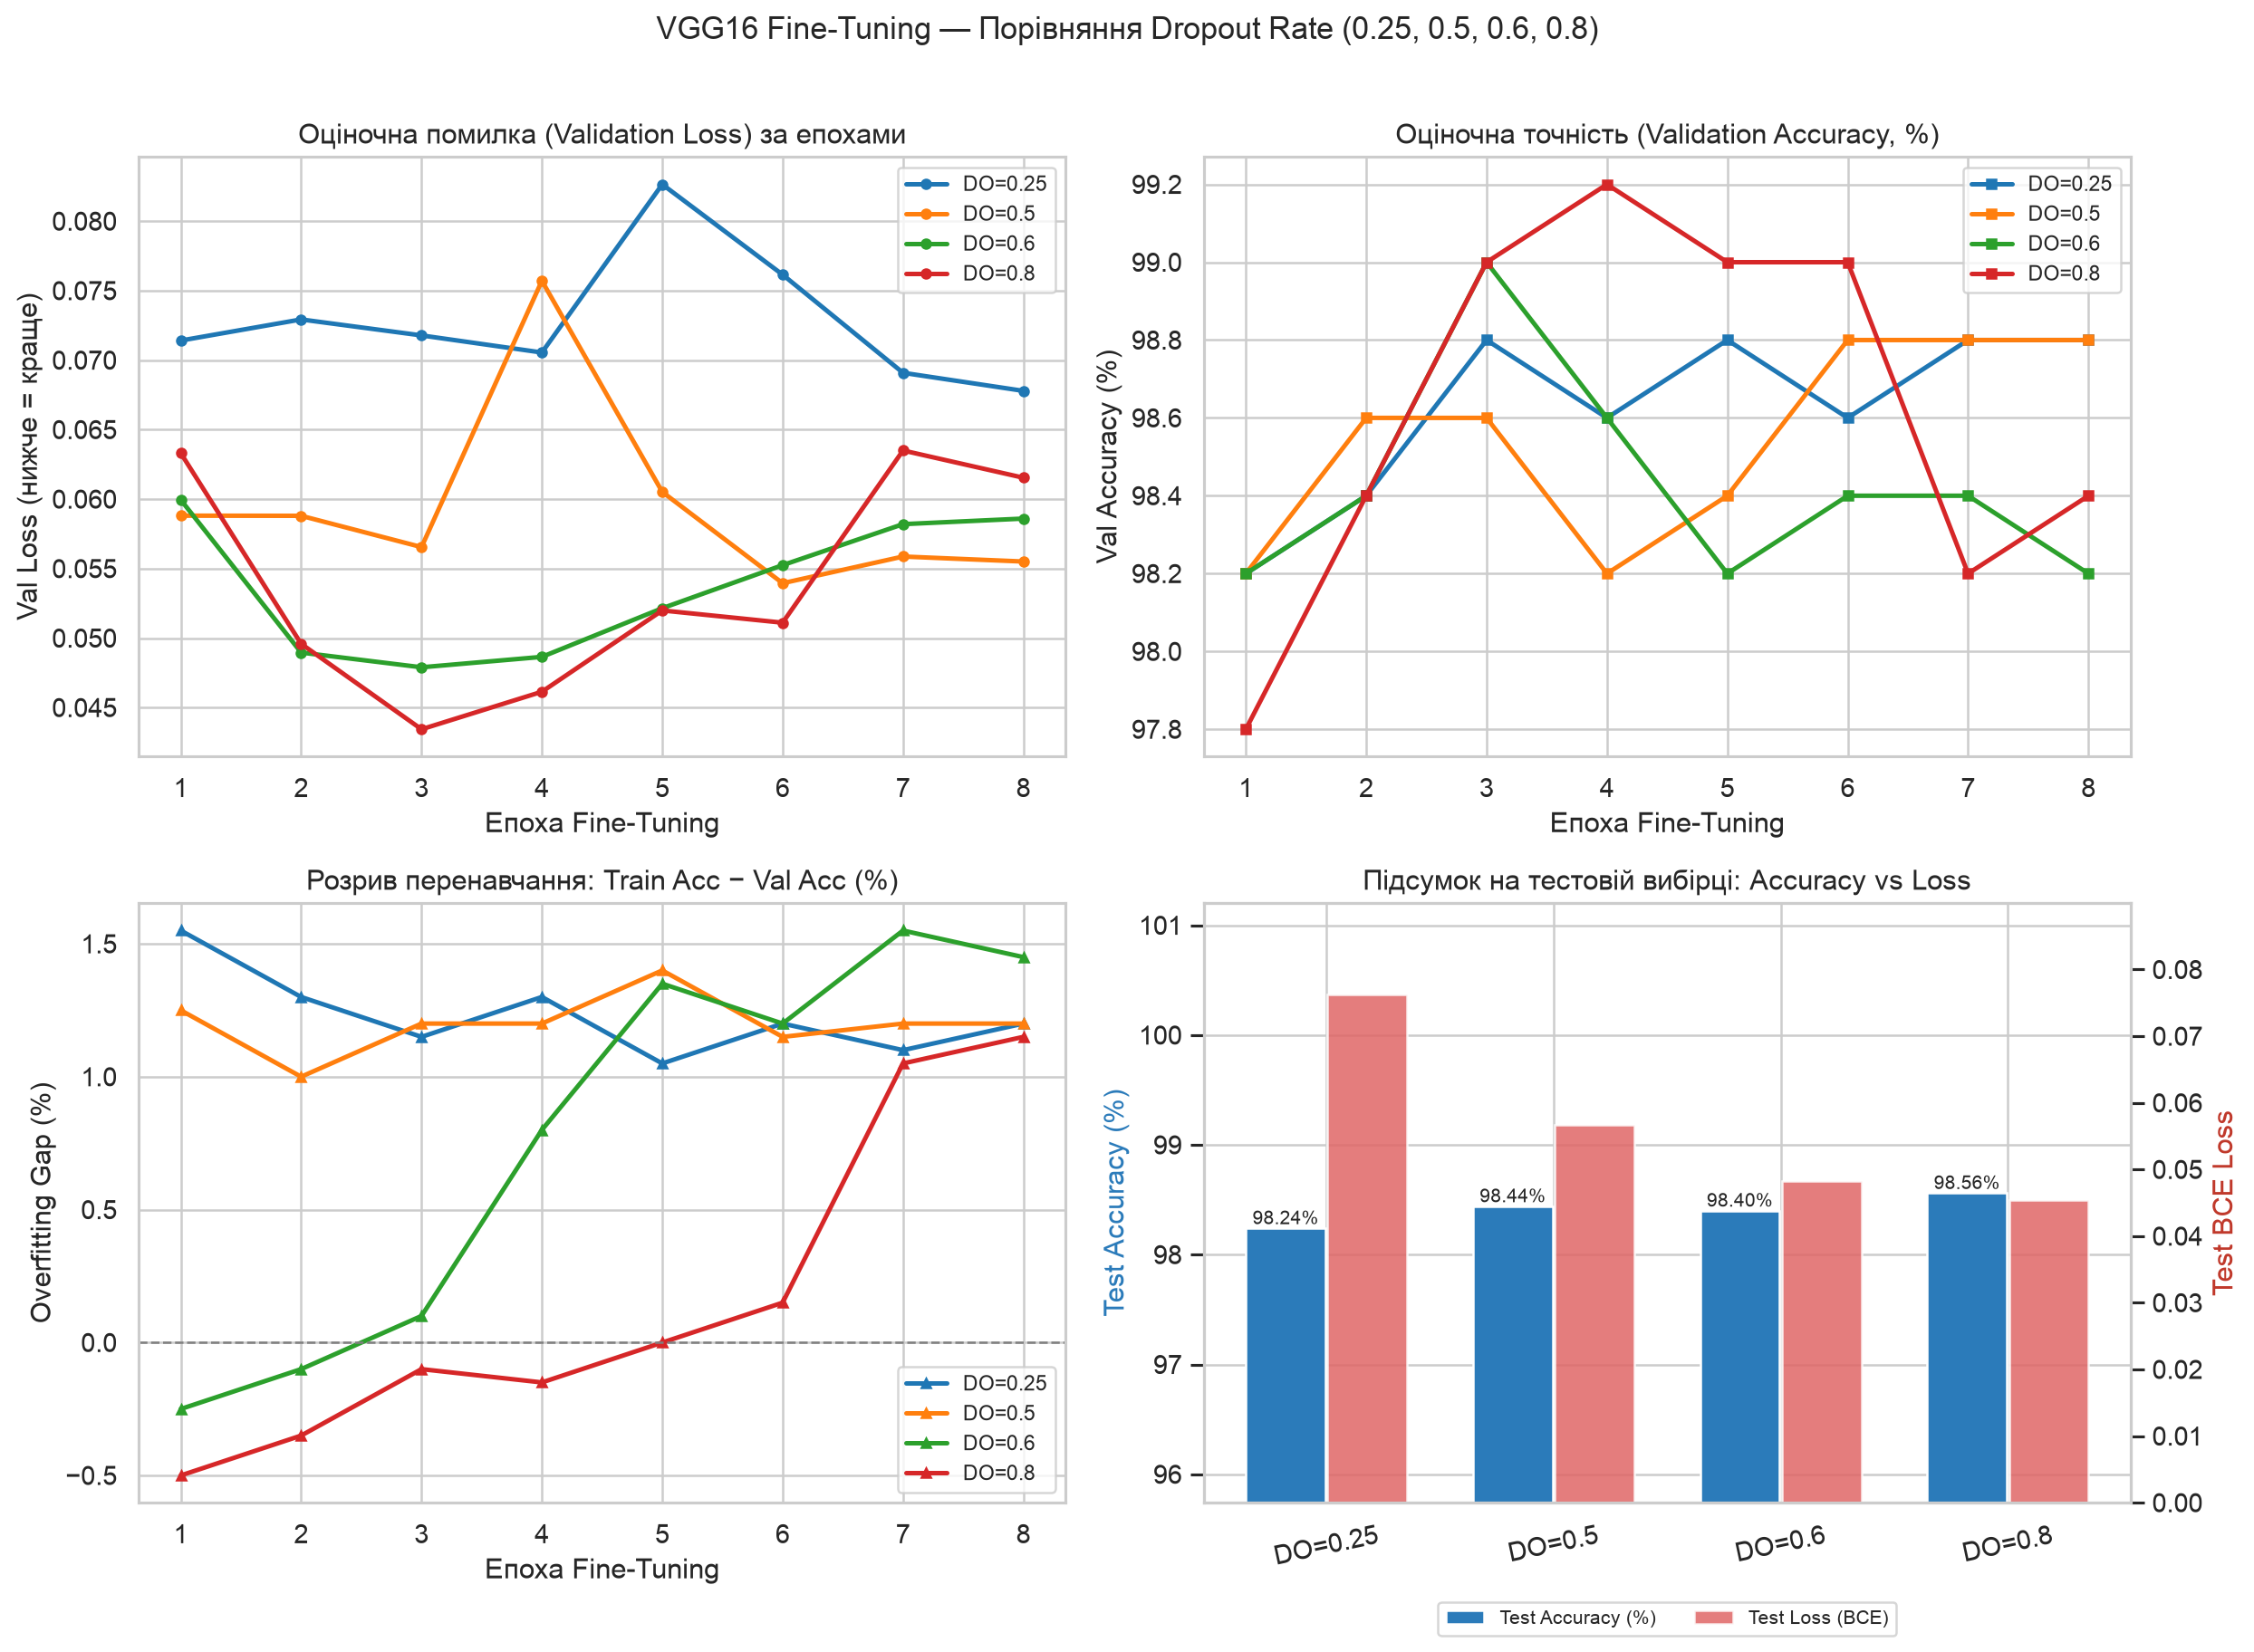

In [5]:
ex1b_records = []
ex1b_rows = []
for do_rate in EX_DROPOUT_RATES:
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=256,
        dropout_rate=do_rate,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"vgg16_ex1b_dropout_{str(do_rate).replace('.', '_')}",
    )
    ex1b_records.append(rec)
    r = _append_study_row("1b. Dropout Rate", str(do_rate), rec)
    ex1b_rows.append({"Dropout Rate": do_rate, **r})

df_ex1b = pd.DataFrame(ex1b_rows)
display(df_ex1b[["Dropout Rate", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_multi_curves_comparison(
    ex1b_records,
    label_fn=lambda r: f"DO={r['dropout_rate']}",
    suptitle="VGG16 Fine-Tuning — Порівняння Dropout Rate (0.25, 0.5, 0.6, 0.8)",
    save_name="01_vgg16_ex1b_dropout.png",
)


[trainer] Loaded existing experiment 'vgg16_ex2_dense2_0' -> Test Acc: 98.44% | Loss: 0.0567
[trainer] Loaded existing experiment 'vgg16_ex2_dense2_32' -> Test Acc: 98.84% | Loss: 0.0431
[trainer] Loaded existing experiment 'vgg16_ex2_dense2_128' -> Test Acc: 98.52% | Loss: 0.0457
[trainer] Loaded existing experiment 'vgg16_ex2_dense2_256' -> Test Acc: 98.64% | Loss: 0.0535


,Second Dense,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,Без 2-го шару,6,0.05395,1.20,98.44,0.0567,0.99857
1,+Dense(32),2,0.03595,0.95,98.84,0.0431,0.99863
2,+Dense(128),2,0.04483,1.20,98.52,0.0457,0.99854
3,+Dense(256),7,0.05288,1.35,98.64,0.0535,0.99869


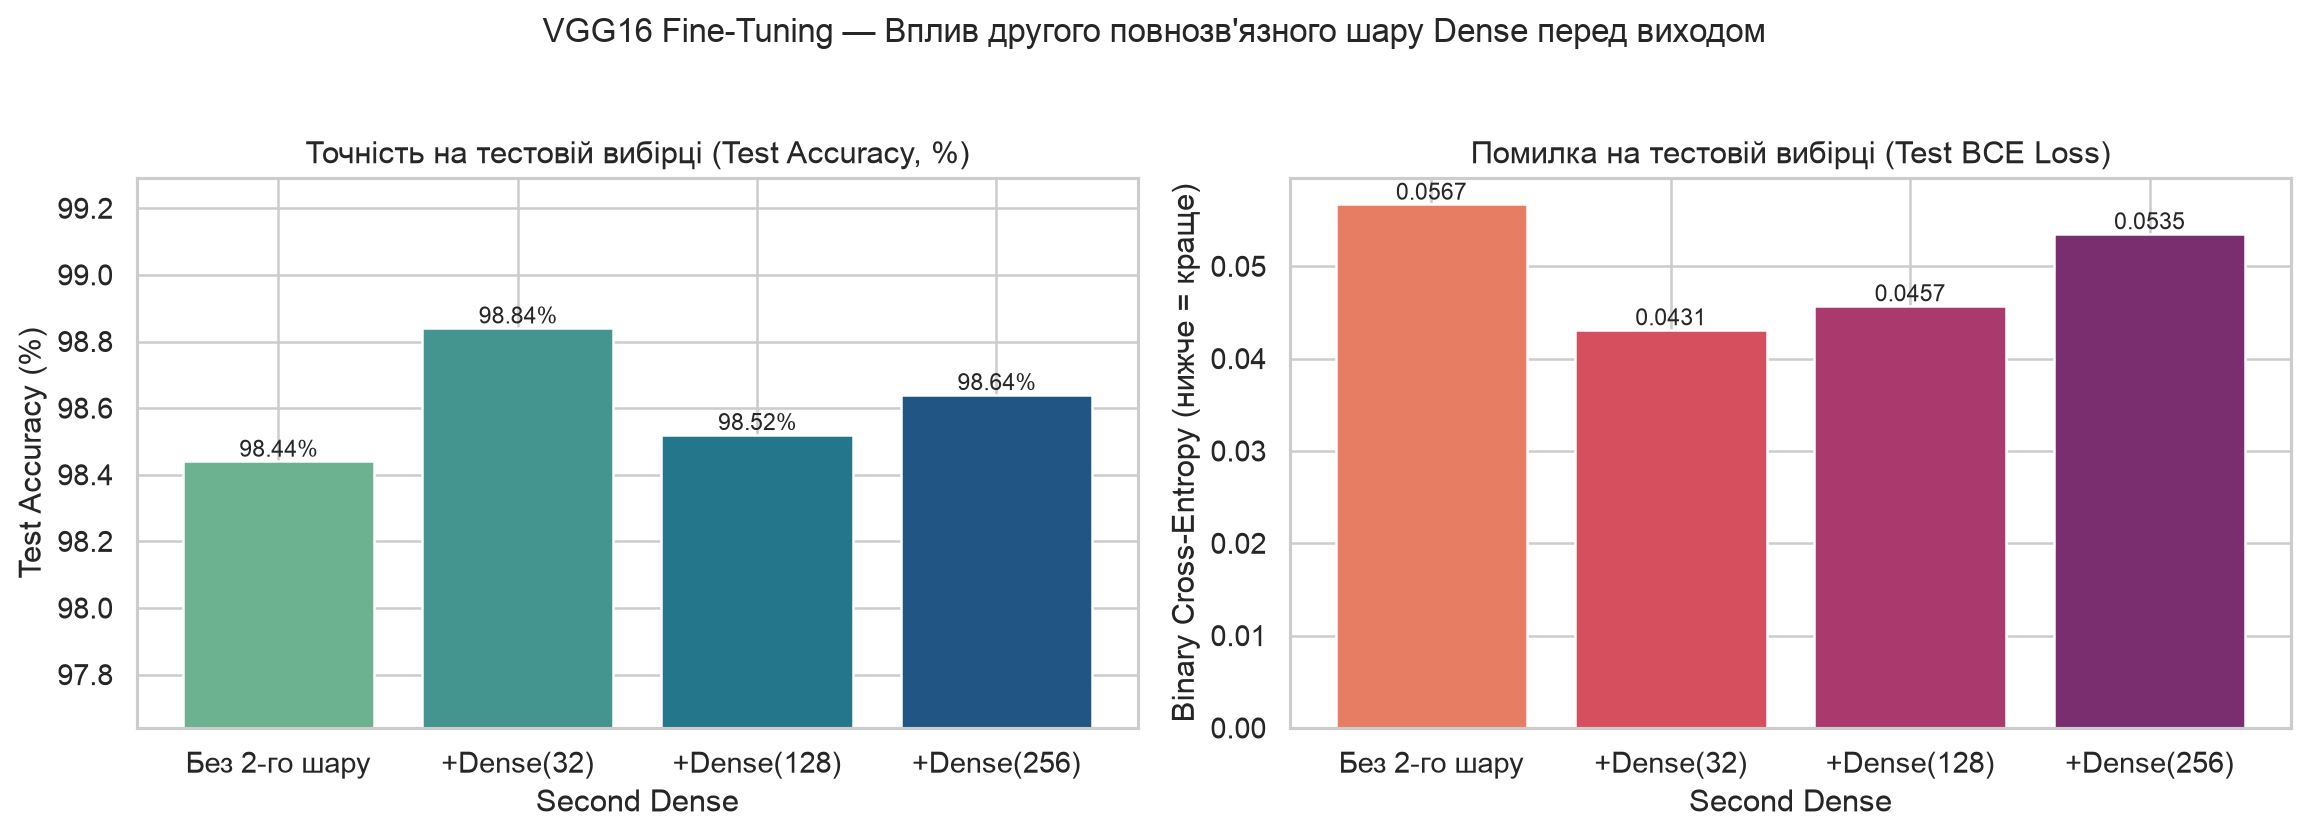

In [6]:
ex2_rows = []
for d2 in EX_SECOND_DENSE_UNITS:
    lbl = "Без 2-го шару" if d2 == 0 else f"+Dense({d2})"
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=256,
        second_dense_units=d2,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"vgg16_ex2_dense2_{d2}",
    )
    r = _append_study_row("2. Second Dense Layer", lbl, rec)
    ex2_rows.append({"Second Dense": lbl, **r})

df_ex2 = pd.DataFrame(ex2_rows)
display(df_ex2[["Second Dense", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_hyperparameter_bars(
    df_ex2,
    x_col="Second Dense",
    title="VGG16 Fine-Tuning — Вплив другого повнозв'язного шару Dense перед виходом",
    save_name="01_vgg16_ex2_second_dense.png",
)


[trainer] Loaded existing experiment 'vgg16_ex3_epochs_25' -> Test Acc: 98.68% | Loss: 0.0736


,Epochs,Best Epoch So Far,Train Acc (%),Val Acc (%),Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,5,3,99.80,98.4,0.05655,1.40,98.72,0.0531,0.99850
1,10,6,100.00,98.8,0.05395,1.20,98.44,0.0567,0.99857
2,15,6,99.95,99.2,0.05395,0.75,98.44,0.0567,0.99857
3,20,19,99.95,98.4,0.04911,1.55,98.68,0.0736,0.99852
4,25,19,99.95,98.8,0.04911,1.15,98.68,0.0736,0.99852


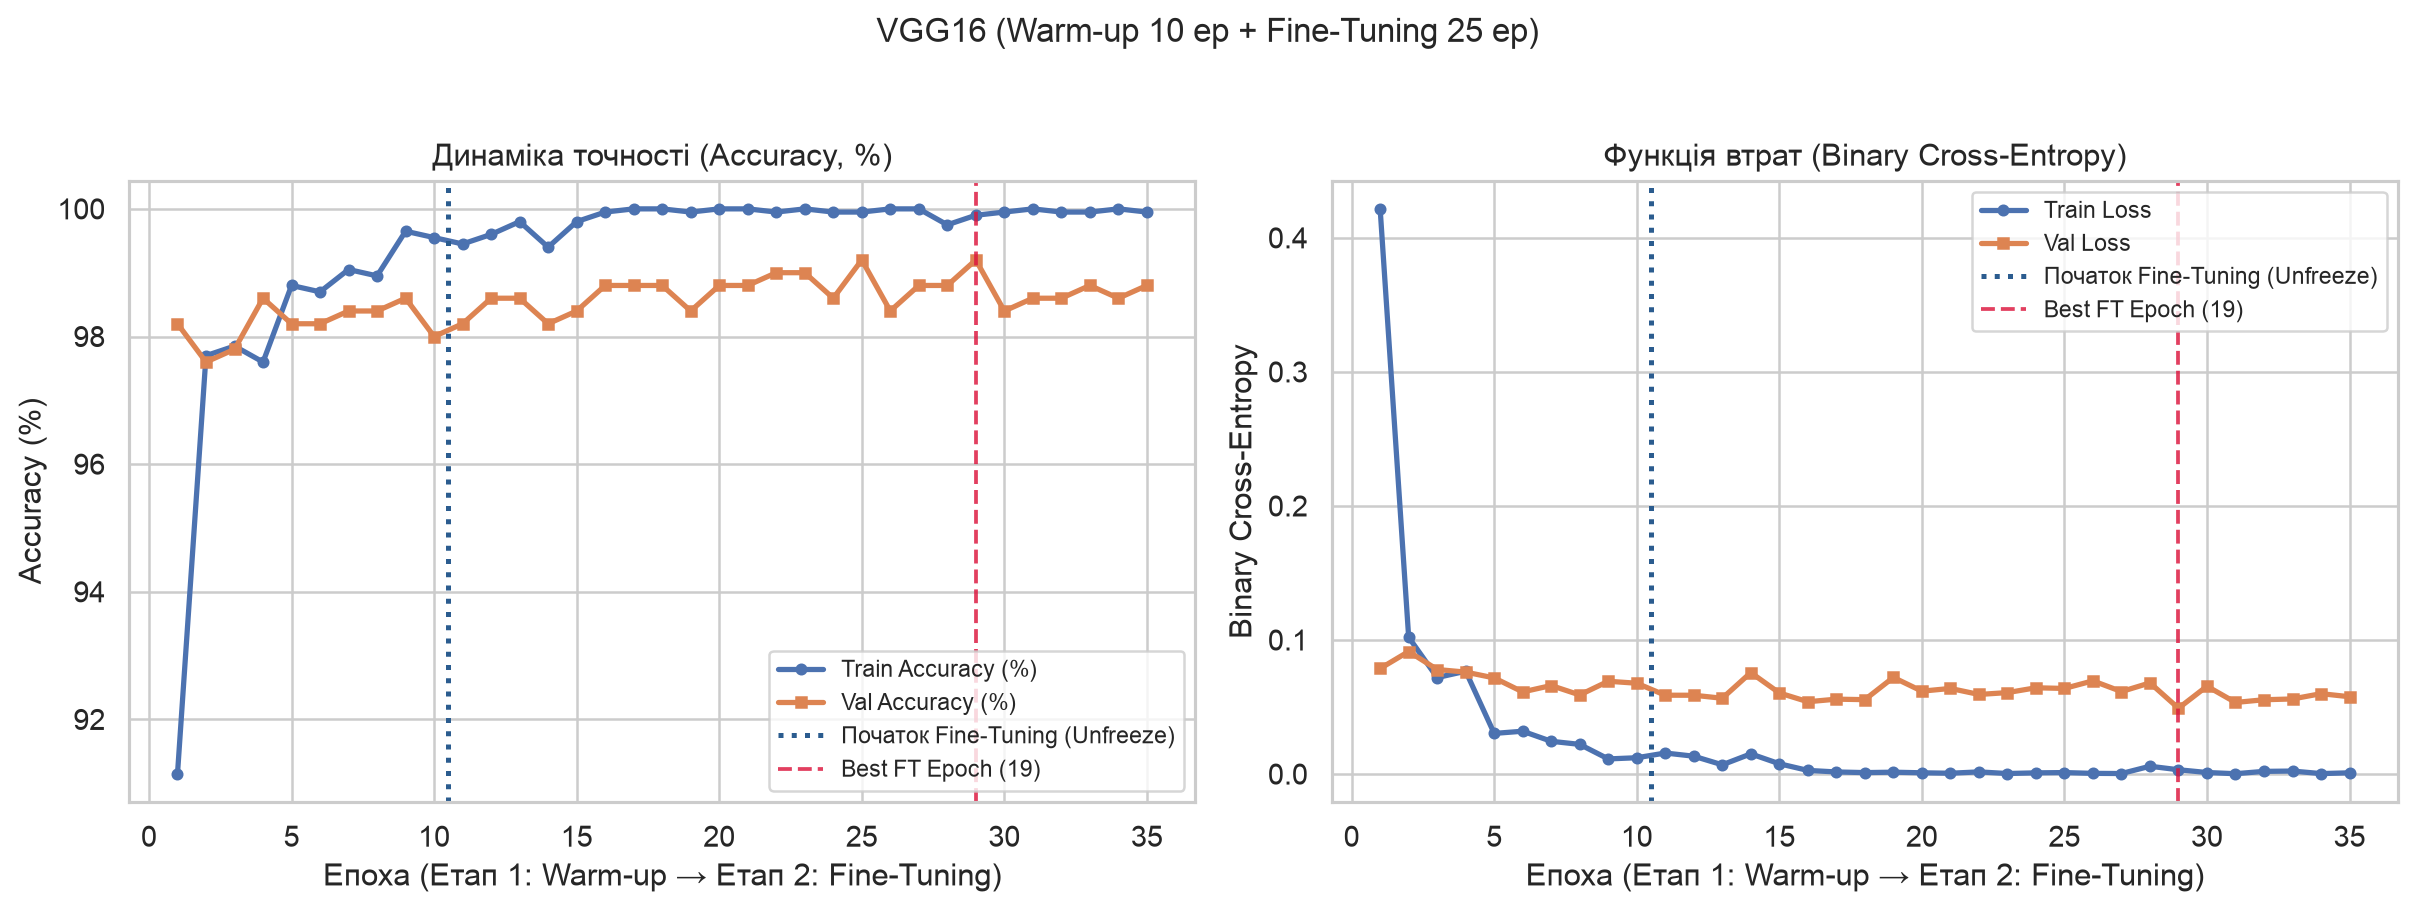

In [7]:
_, rec_ep25 = run_finetuning_experiment(
    model_key="vgg16",
    bottleneck_features=vgg_bottleneck,
    prefix_cache=vgg_prefix_b1,
    unfreeze_blocks=1,
    dense_units=256,
    dropout_rate=0.5,
    optimizer_name="adam",
    learning_rate=1e-5,
    batch_size=50,
    warmup_epochs=10,
    finetune_epochs=25,
    milestone_epochs=EX_EPOCH_CHECKPOINTS,
    experiment_name="vgg16_ex3_epochs_25",
)

ex3_rows = []
for ms in rec_ep25["milestones"]:
    tm = ms["test_metrics"]
    row_ep = {
        "Epochs": ms["epochs_budget"],
        "Best Epoch So Far": ms["best_epoch_so_far"],
        "Train Acc (%)": round(ms["train_accuracy"] * 100, 2),
        "Val Acc (%)": round(ms["val_accuracy"] * 100, 2),
        "Best Val Loss": ms["best_val_loss"],
        "Overfit Gap (%)": round(ms["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
    }
    ex3_rows.append(row_ep)
    all_study_rows.append({
        "Study Group": "3. Epochs Budget",
        "Setting": f"{ms['epochs_budget']} epochs",
        "Unfrozen Blocks": 1,
        "Dense 1": 256,
        "Dense 2": 0,
        "Dropout": 0.5,
        "Optimizer": "ADAM",
        "Learning Rate": 1e-5,
        "Batch Size": 50,
        "FT Epochs": ms["epochs_budget"],
        "Best Epoch": ms["best_epoch_so_far"],
        "Best Val Loss": ms["best_val_loss"],
        "Overfit Gap (%)": row_ep["Overfit Gap (%)"],
        "Test Accuracy (%)": row_ep["Test Accuracy (%)"],
        "Test Loss": row_ep["Test Loss"],
        "ROC-AUC": row_ep["ROC-AUC"],
        "Test Errors": tm["errors_count"],
        "FT Time (s)": round(rec_ep25["finetune_seconds"] * ms["epochs_budget"] / 25.0, 2),
    })

df_ex3 = pd.DataFrame(ex3_rows)
display(df_ex3)
plot_two_stage_curves(
    rec_ep25,
    title_prefix="VGG16 (Warm-up 10 ep + Fine-Tuning 25 ep)",
    save_name="01_vgg16_ex3_epochs_25_curves.png",
)


[trainer] Loaded existing experiment 'vgg16_ex4_batch_25' -> Test Acc: 98.64% | Loss: 0.0530
[trainer] Loaded existing experiment 'vgg16_ex4_batch_50' -> Test Acc: 98.44% | Loss: 0.0567
[trainer] Loaded existing experiment 'vgg16_ex4_batch_100' -> Test Acc: 98.64% | Loss: 0.0582
[trainer] Loaded existing experiment 'vgg16_ex4_batch_125' -> Test Acc: 98.52% | Loss: 0.0578


,Batch Size,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,FT Time (s)
0,25,4,0.05714,2.30,98.64,0.0530,109.46
1,50,6,0.05395,1.20,98.44,0.0567,100.61
2,100,5,0.04823,1.35,98.64,0.0582,91.76
3,125,5,0.06114,1.35,98.52,0.0578,90.92


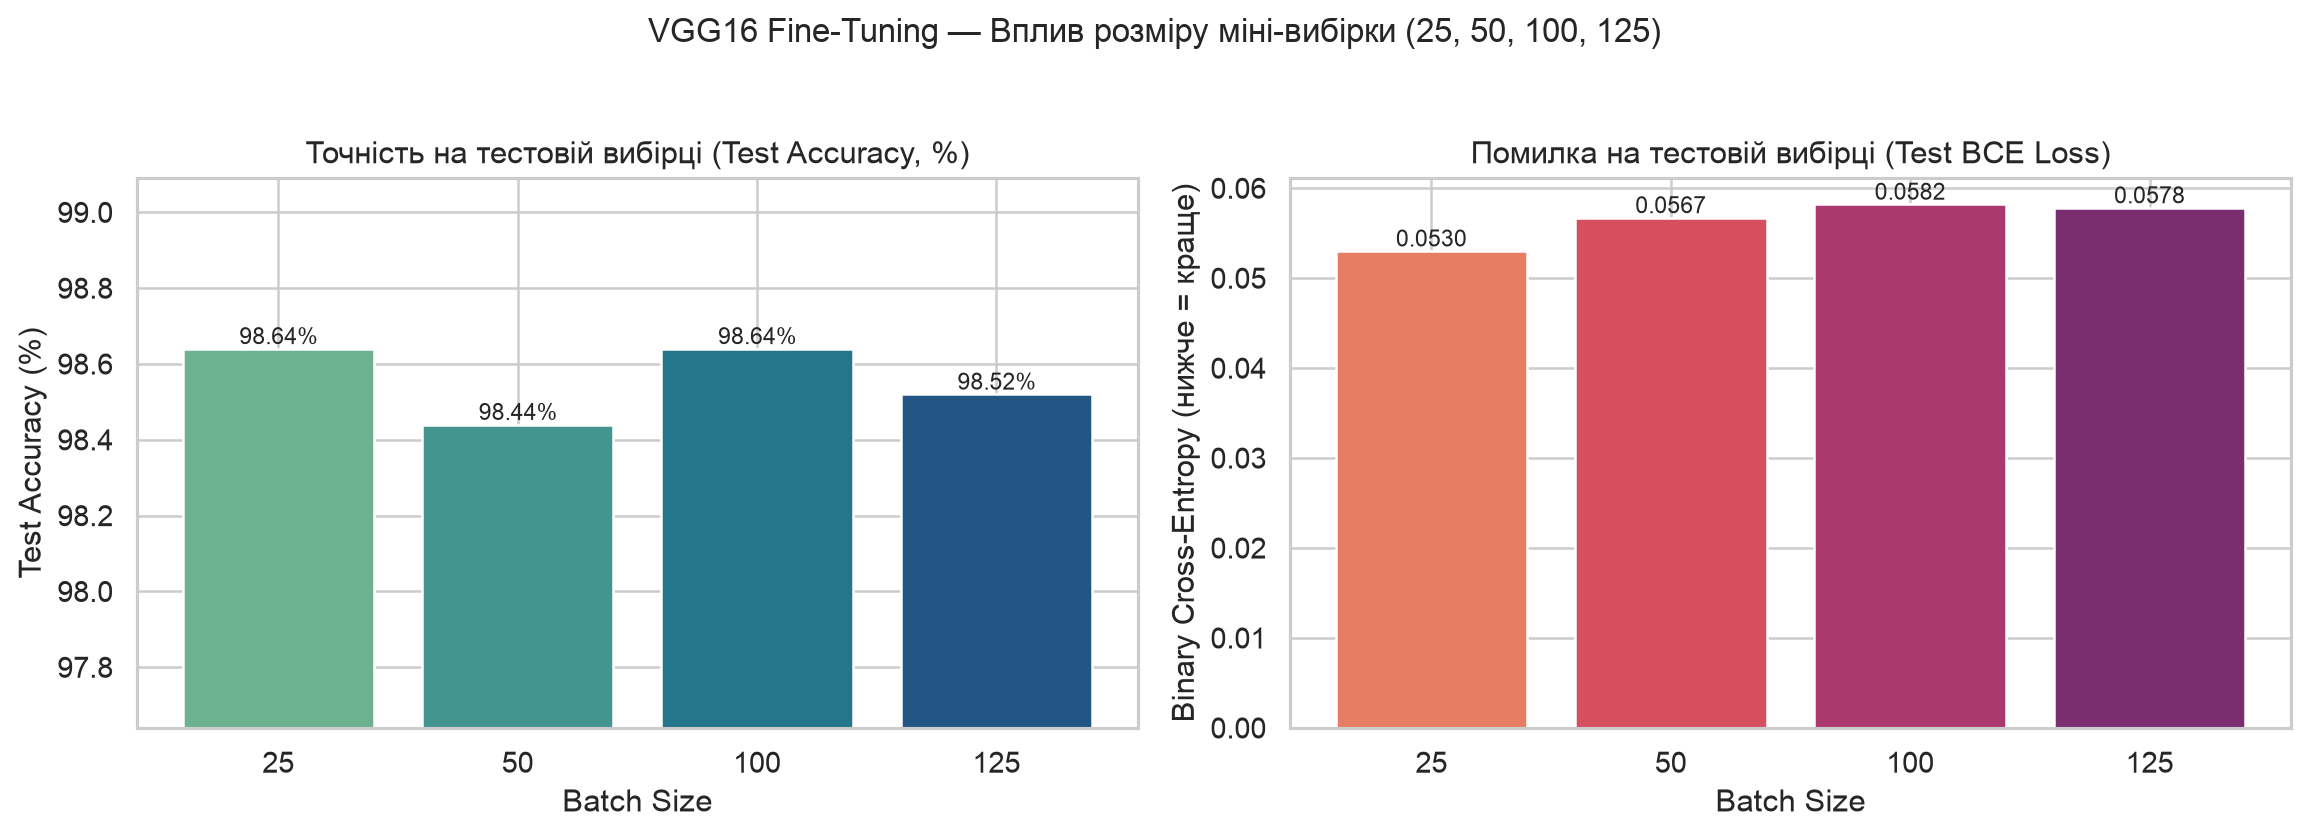

In [8]:
ex4_rows = []
for bsz in EX_BATCH_SIZES:
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=bsz,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"vgg16_ex4_batch_{bsz}",
    )
    r = _append_study_row("4. Mini-Batch Size", str(bsz), rec)
    ex4_rows.append({"Batch Size": bsz, **r})

df_ex4 = pd.DataFrame(ex4_rows)
display(df_ex4[["Batch Size", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "FT Time (s)"]])
plot_hyperparameter_bars(
    df_ex4,
    x_col="Batch Size",
    title="VGG16 Fine-Tuning — Вплив розміру міні-вибірки (25, 50, 100, 125)",
    save_name="01_vgg16_ex4_batch_size.png",
)


[trainer] Loaded existing experiment 'vgg16_ex5_opt_sgd' -> Test Acc: 98.36% | Loss: 0.0626
[trainer] Loaded existing experiment 'vgg16_ex5_opt_adam' -> Test Acc: 98.44% | Loss: 0.0567
[trainer] Loaded existing experiment 'vgg16_ex5_opt_rmsprop' -> Test Acc: 98.52% | Loss: 0.0621


,Optimizer,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,SGD,5,0.05874,1.25,98.36,0.0626,0.99814
1,ADAM,6,0.05395,1.20,98.44,0.0567,0.99857
2,RMSPROP,1,0.05784,1.20,98.52,0.0621,0.99838


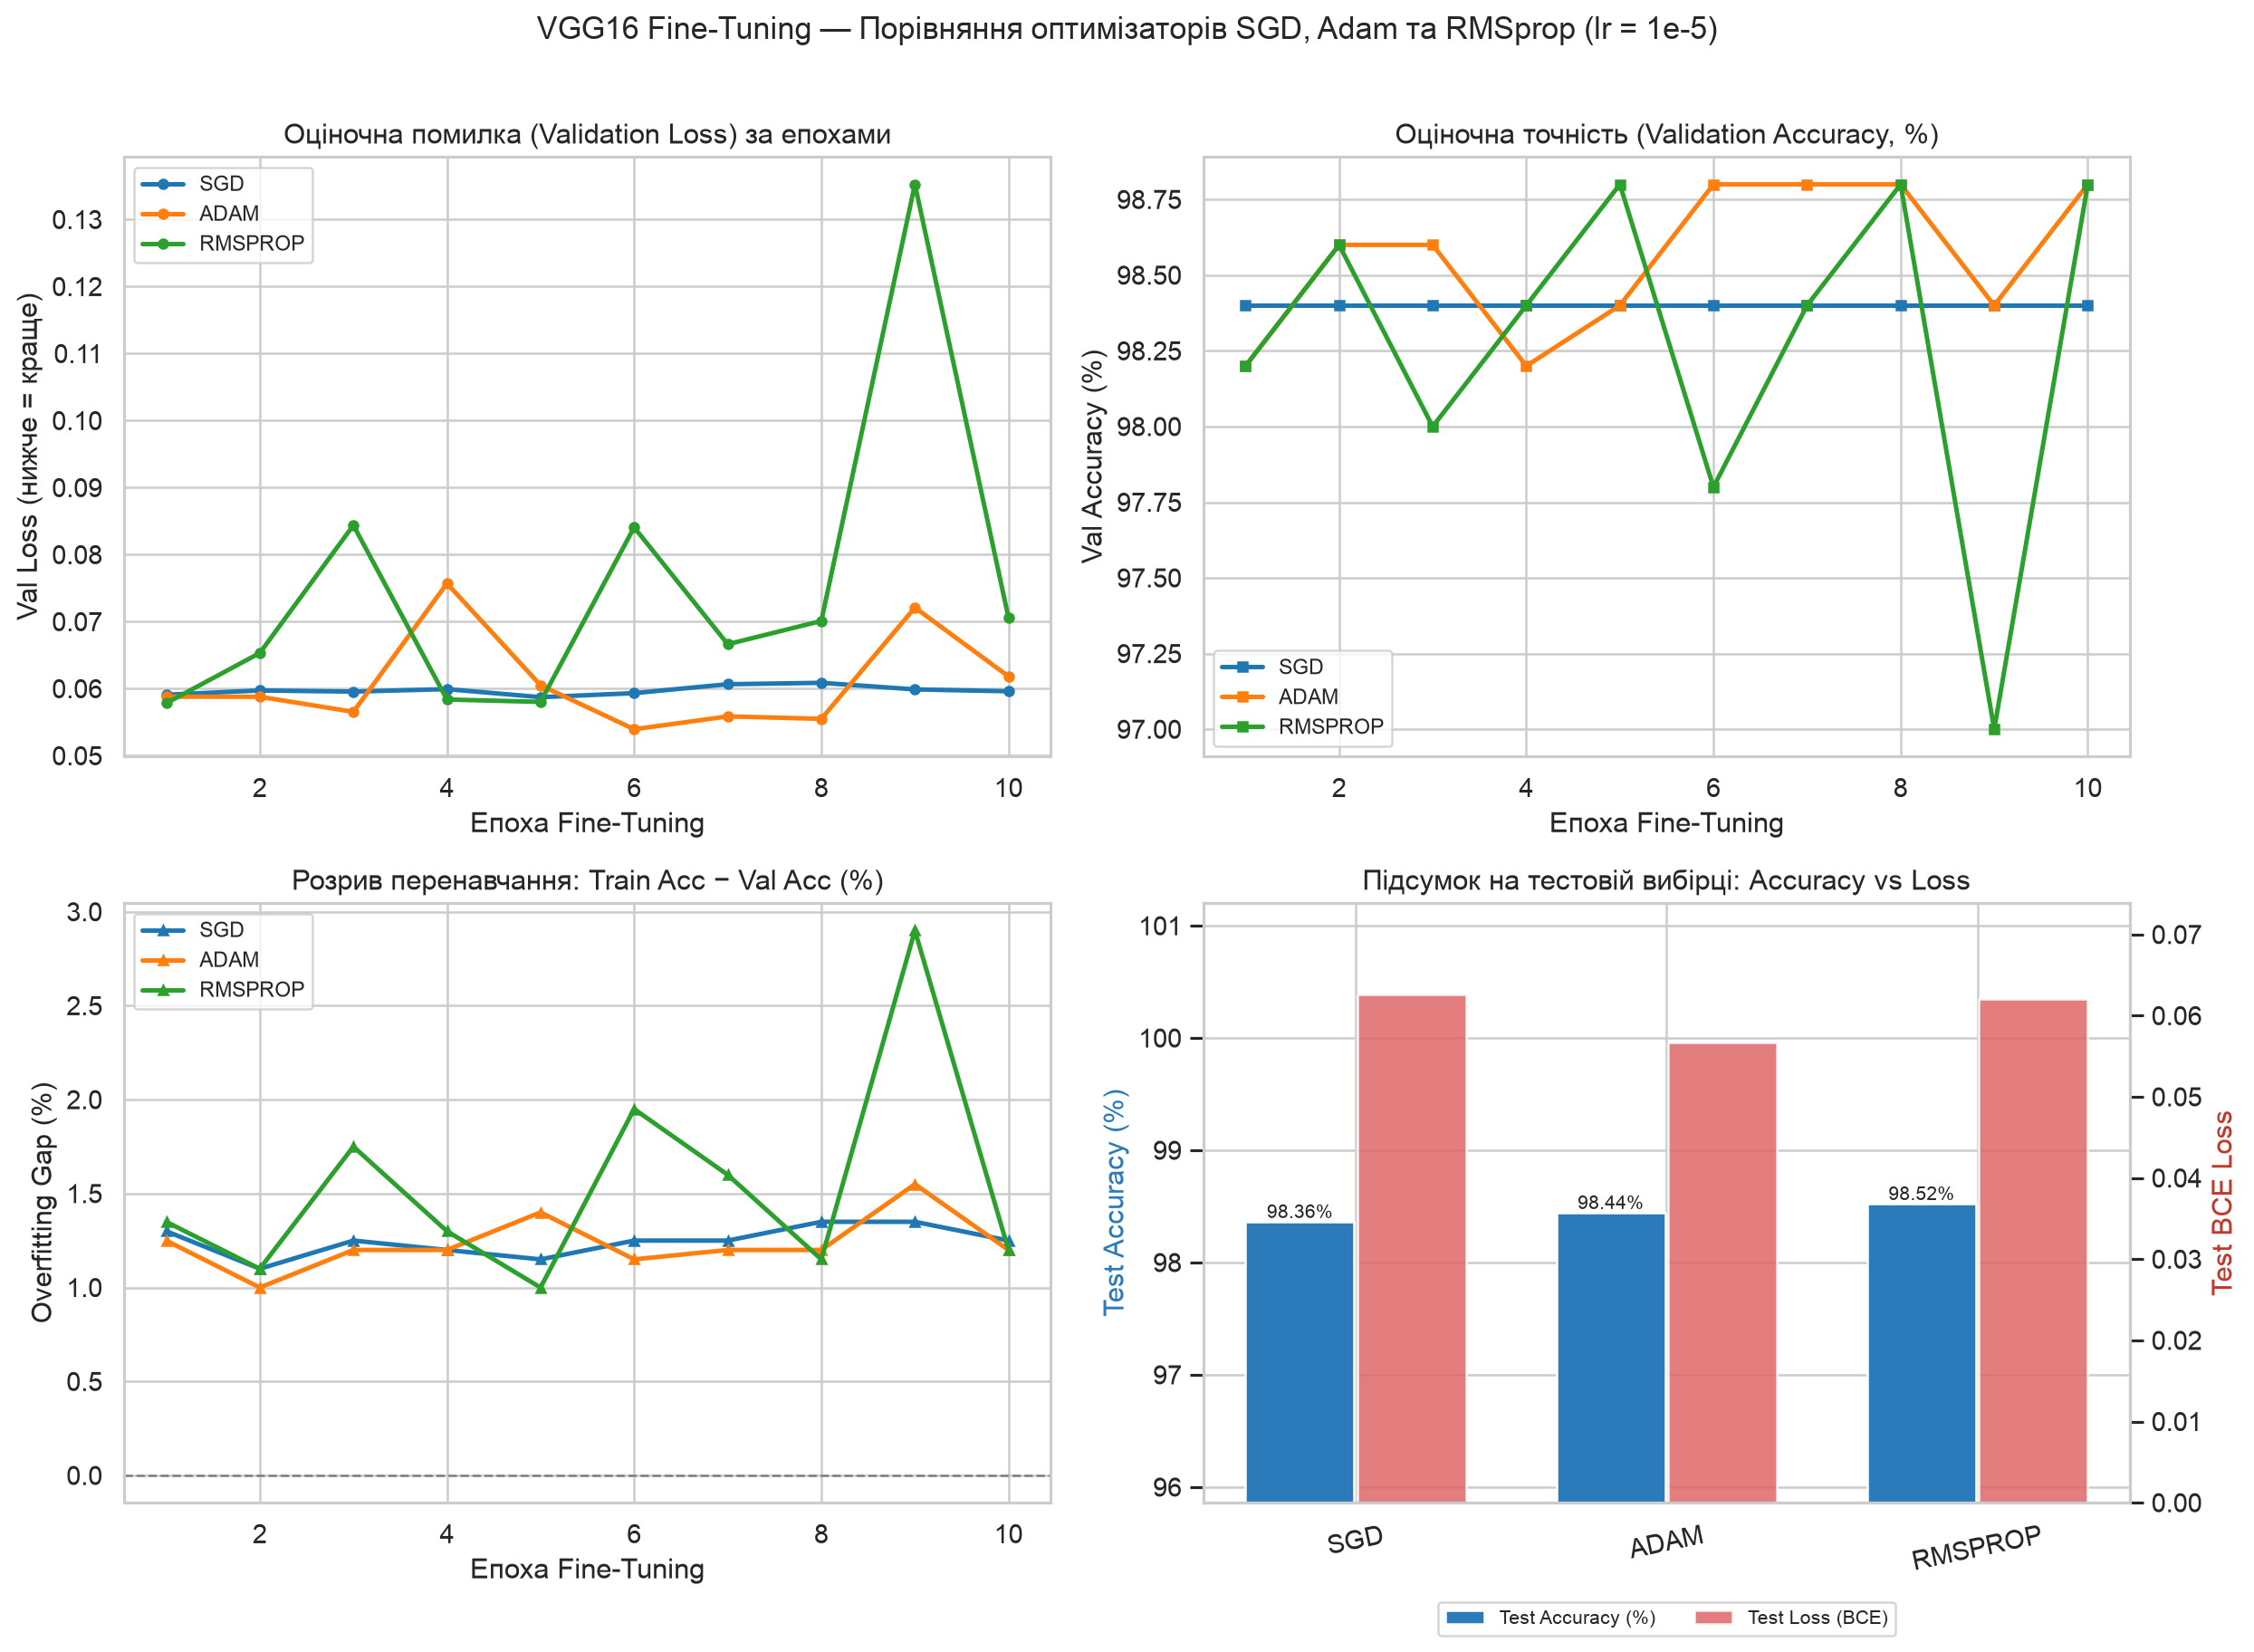

In [9]:
ex5_records = []
ex5_rows = []
for opt_name in EX_OPTIMIZERS:
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name=opt_name,
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=10,
        experiment_name=f"vgg16_ex5_opt_{opt_name}",
    )
    ex5_records.append(rec)
    r = _append_study_row("5. Optimizer", opt_name.upper(), rec)
    ex5_rows.append({"Optimizer": opt_name.upper(), **r})

df_ex5 = pd.DataFrame(ex5_rows)
display(df_ex5[["Optimizer", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_multi_curves_comparison(
    ex5_records,
    label_fn=lambda r: r["optimizer"].upper(),
    suptitle="VGG16 Fine-Tuning — Порівняння оптимізаторів SGD, Adam та RMSprop (lr = 1e-5)",
    save_name="01_vgg16_ex5_optimizers.png",
)


[trainer] Loaded existing experiment 'vgg16_ex6_lr_1e-03' -> Test Acc: 50.00% | Loss: 8.0590
[trainer] vgg16_ex6_lr_1e-04 | Best FT Ep 1/10 | Val Loss: 0.0529 | Test Acc: 97.80% (55 errs) | Time: 122.9s
[trainer] vgg16_ex6_lr_1e-05 | Best FT Ep 6/10 | Val Loss: 0.0539 | Test Acc: 98.44% (39 errs) | Time: 120.3s
[trainer] vgg16_ex6_lr_1e-06 | Best FT Ep 5/10 | Val Loss: 0.0566 | Test Acc: 98.44% (39 errs) | Time: 120.7s


,Learning Rate,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,0.001000,1,8.05905,0.0,50.00,8.0590,0.50000
1,0.000100,1,0.05290,1.0,97.80,0.0680,0.99793
2,0.000010,6,0.05395,1.2,98.44,0.0567,0.99857
3,0.000001,5,0.05662,1.4,98.44,0.0612,0.99827


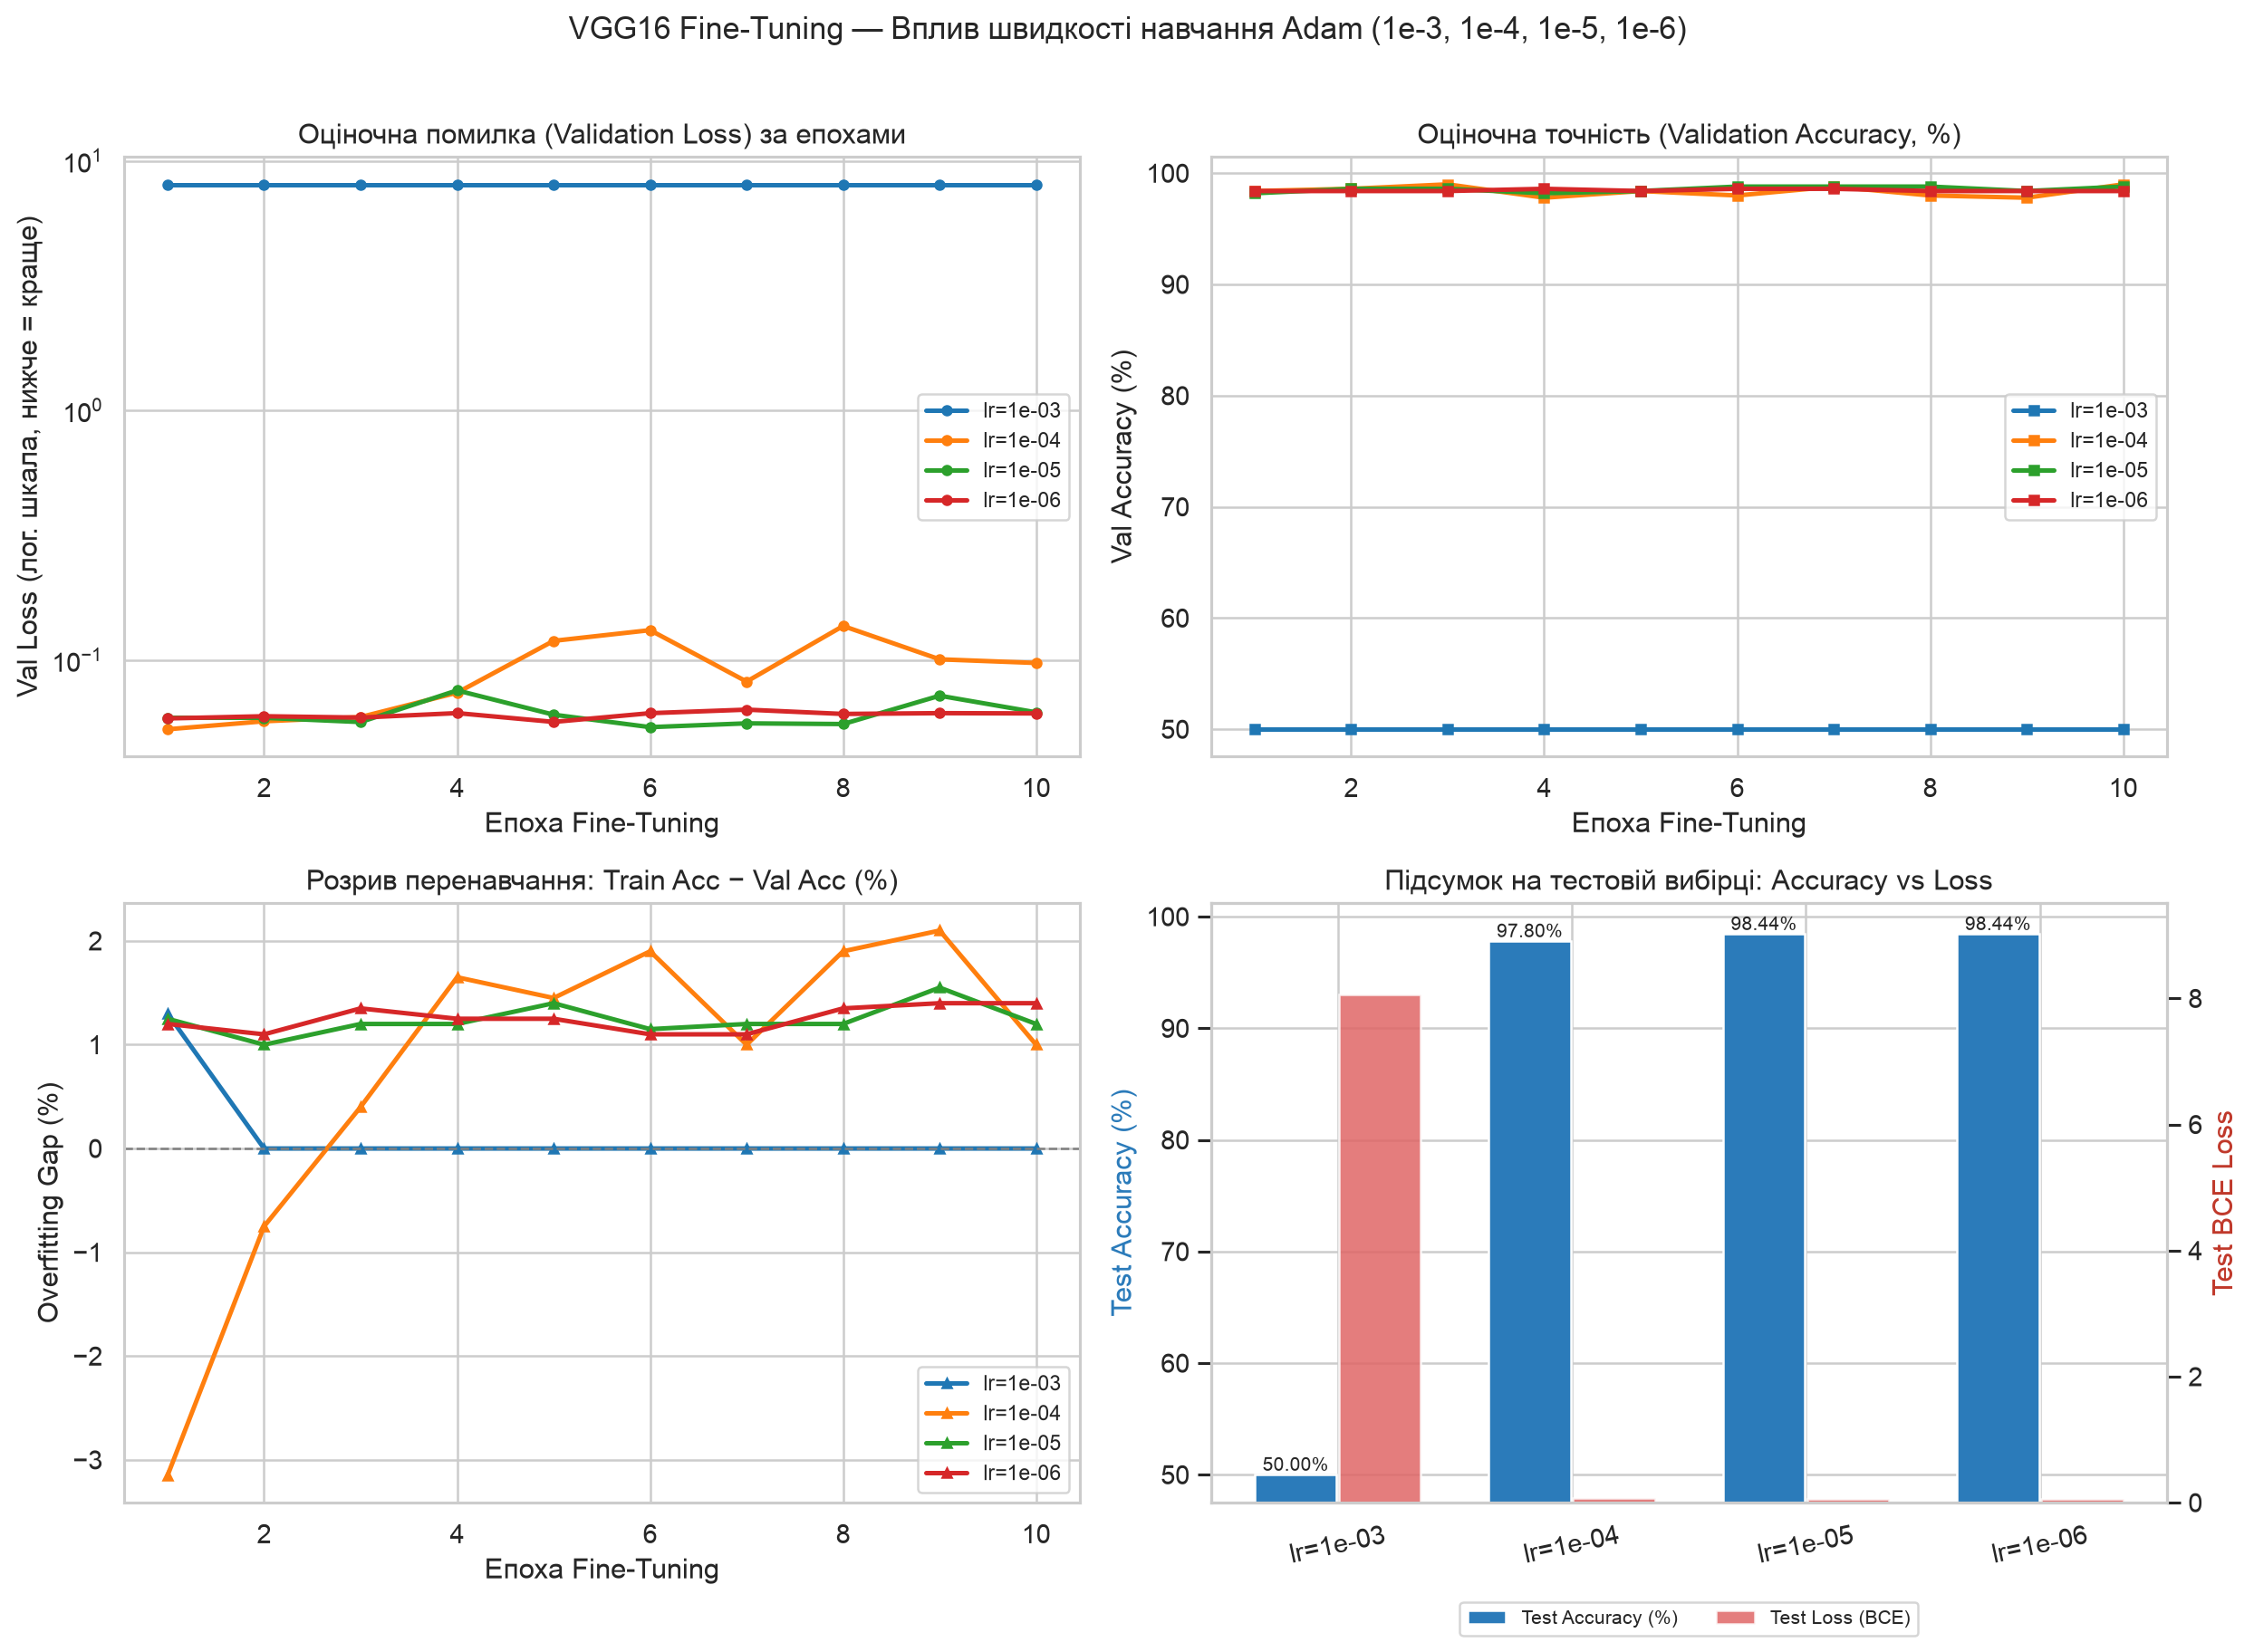

In [10]:
ex6_records = []
ex6_rows = []
for lr_val in EX_ADAM_LRS:
    lr_tag = f"{lr_val:.0e}"
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=vgg_prefix_b1,
        unfreeze_blocks=1,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=lr_val,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=10,
        experiment_name=f"vgg16_ex6_lr_{lr_tag}",
    )
    ex6_records.append(rec)
    r = _append_study_row("6. Adam Learning Rate", lr_tag, rec)
    ex6_rows.append({"Learning Rate": lr_tag, **r})

df_ex6 = pd.DataFrame(ex6_rows)
display(df_ex6[["Learning Rate", "Best Epoch", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_multi_curves_comparison(
    ex6_records,
    label_fn=lambda r: f"lr={r['learning_rate']:.0e}",
    suptitle="VGG16 Fine-Tuning — Вплив швидкості навчання Adam (1e-3, 1e-4, 1e-5, 1e-6)",
    save_name="01_vgg16_ex6_learning_rates.png",
)


[trainer] vgg16_ex7_blocks_1 | Best FT Ep 6/8 | Val Loss: 0.0539 | Test Acc: 98.44% (39 errs) | Time: 97.2s
[trainer] Caching frozen prefix 'vgg16:block3_pool' shape=(256, 28, 28) (2000 tr / 500 val / 2502 test, temp disk=1.87 GB) ...
[trainer] vgg16_ex7_blocks_2 | Best FT Ep 1/8 | Val Loss: 0.0478 | Test Acc: 98.08% (48 errs) | Time: 422.5s
[trainer] Caching frozen prefix 'vgg16:block2_pool' shape=(128, 56, 56) (2000 tr / 500 val / 2502 test, temp disk=3.74 GB) ...
[trainer] vgg16_ex7_blocks_3 | Best FT Ep 1/8 | Val Loss: 0.0463 | Test Acc: 97.92% (52 errs) | Time: 884.2s
Збережено таблицю підбору гіперпараметрів (32 запусків): /Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab8/lab9/results/vgg16_hyperparameter_studies.csv


Prefix [vgg16:test]: 100%|##########| 79/79 [00:34<00:00,  2.26it/s]


,Unfrozen Blocks Label,Trainable Params,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,1 блок(и),7211009,0.05395,1.20,98.44,0.0567,0.99857
1,2 блок(и),13110785,0.04779,1.20,98.08,0.0716,0.99802
2,3 блок(и),14586113,0.04631,1.15,97.92,0.0758,0.99785


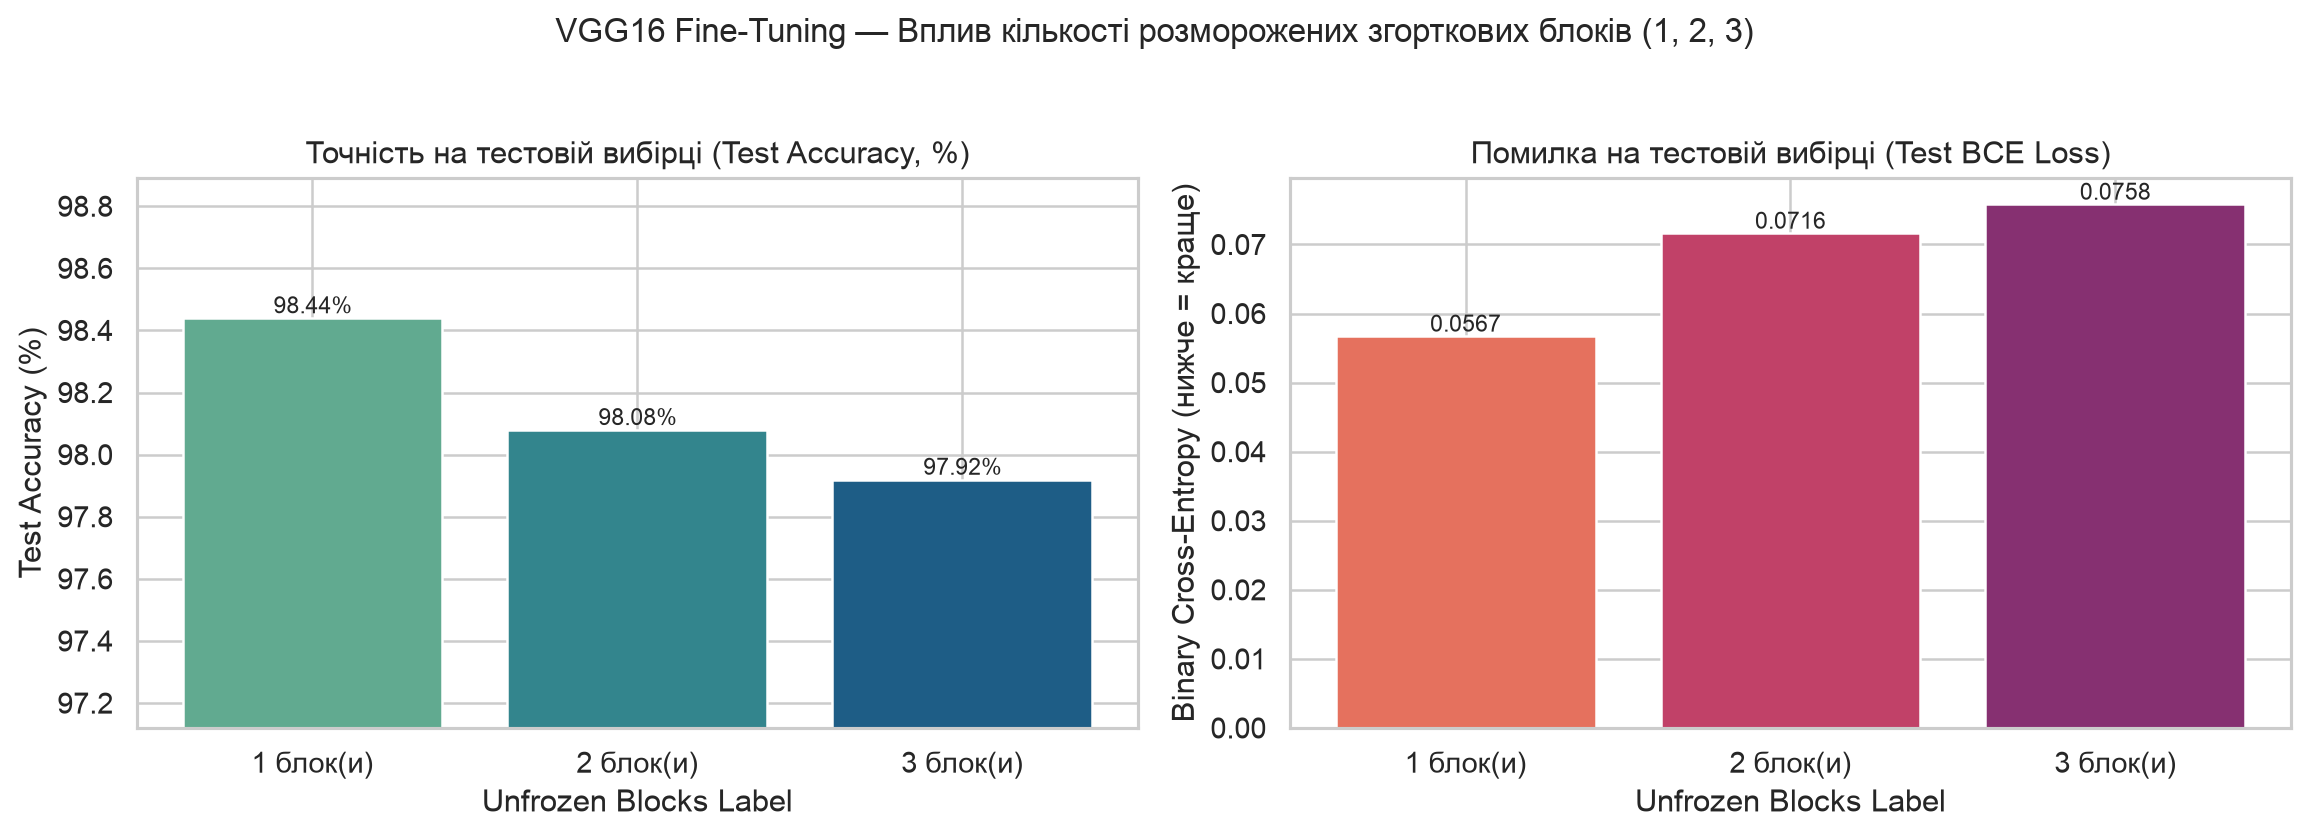

In [ ]:
ex7_records = []
ex7_rows = []
for n_blk in EX_UNFREEZE_BLOCKS:
    pc_blk = (
        vgg_prefix_b1
        if n_blk == 1
        else prepare_prefix_cache("vgg16", unfreeze_blocks=n_blk, train_samples=2000, val_samples=500)
    )
    _, rec = run_finetuning_experiment(
        model_key="vgg16",
        bottleneck_features=vgg_bottleneck,
        prefix_cache=pc_blk,
        unfreeze_blocks=n_blk,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"vgg16_ex7_blocks_{n_blk}",
    )
    ex7_records.append(rec)
    lbl = f"{n_blk} блок(и)"
    r = _append_study_row("7. Unfrozen Blocks", lbl, rec)
    ex7_rows.append({"Unfrozen Blocks Label": lbl, "Trainable Params": rec["trainable_params"], **r})

cleanup_temp_prefix_cache()
df_ex7 = pd.DataFrame(ex7_rows)
display(df_ex7[["Unfrozen Blocks Label", "Trainable Params", "Best Val Loss", "Overfit Gap (%)", "Test Accuracy (%)", "Test Loss", "ROC-AUC"]])
plot_hyperparameter_bars(
    df_ex7,
    x_col="Unfrozen Blocks Label",
    title="VGG16 Fine-Tuning — Вплив кількості розморожених згорткових блоків (1, 2, 3)",
    save_name="01_vgg16_ex7_unfreeze_blocks.png",
)

df_all_studies = pd.DataFrame(all_study_rows)
df_all_studies.to_csv(RESULTS_DIR / "vgg16_hyperparameter_studies.csv", index=False)
print(f"Збережено таблицю підбору гіперпараметрів ({len(df_all_studies)} запусків): {RESULTS_DIR / 'vgg16_hyperparameter_studies.csv'}")


Обрана конфігурація голови VGG16 за мінімумом Val Loss: Dense=256, Dense2=32, Dropout=0.6, lr=5e-6
[trainer] Caching frozen prefix 'vgg16:block4_pool' shape=(512, 14, 14) (6000 tr / 2498 val / 2502 test, temp disk=2.06 GB) ...
[trainer] vgg16_champion_finetuned | Best FT Ep 3/8 | Val Loss: 0.0326 | Test Acc: 99.08% (23 errs) | Time: 370.2s
Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
[trainer] Verified End-to-End VGG16 on raw test JPEGs (max prob diff vs FP16 prefix split = 0.00007).
[trainer] Saved vgg16_finetuned.keras (56.76 MB) | Test Acc: 99.08% (23 errs / 2502) | Loss: 0.0310 | ROC-AUC: 0.99916


Prefix [vgg16:test]: 100%|##########| 79/79 [00:57<00:00,  1.39it/s]


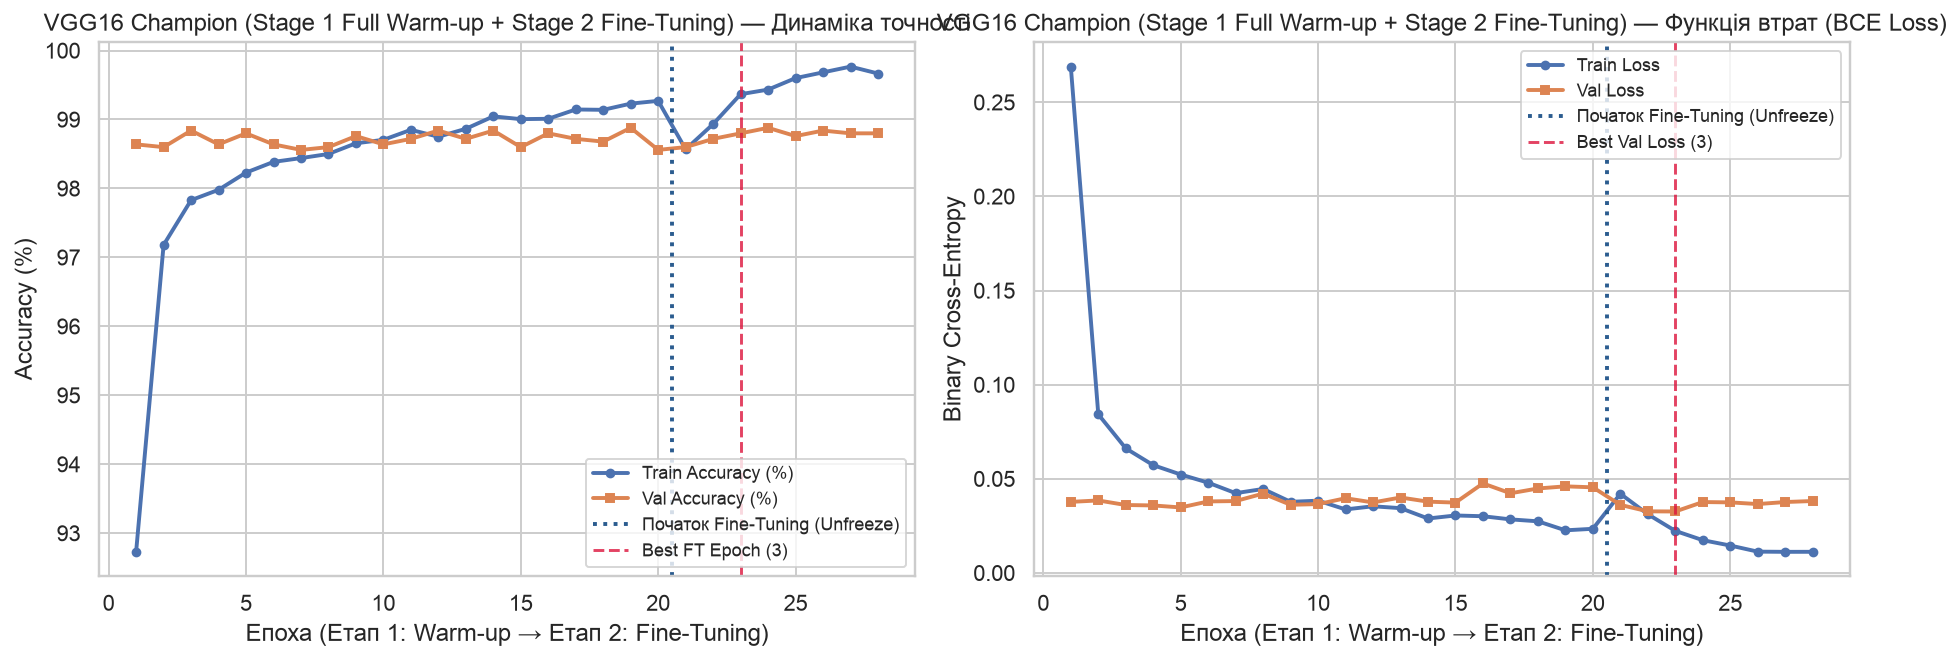

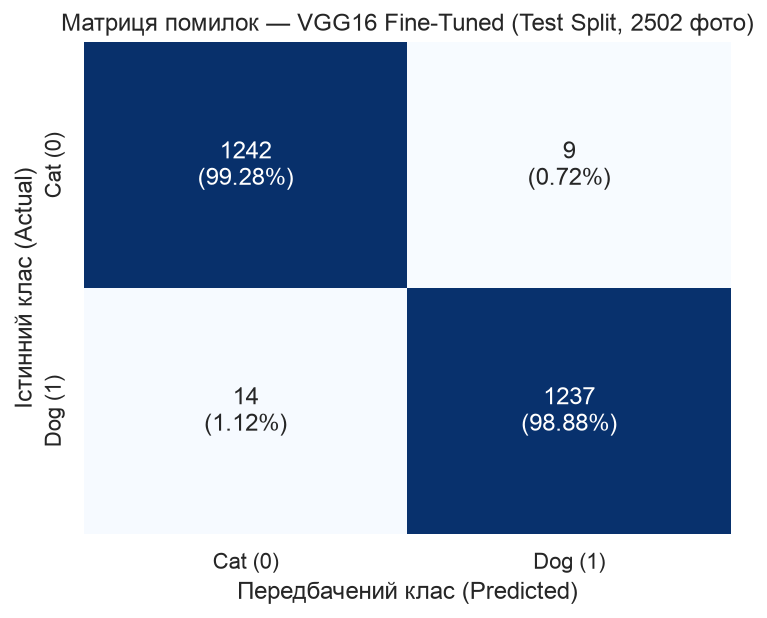

,filename,rel_path,true_class,pred_class,dog_probability,confidence,bce_loss,correct
0,ext_cat_01_tabby.jpg,cats/ext_cat_01_tabby.jpg,cats,cats,0.00000,1.00000,0.00000,True
1,ext_cat_02_orange.jpg,cats/ext_cat_02_orange.jpg,cats,cats,0.00074,0.99926,0.00074,True
2,ext_cat_03_white_cat.jpg,cats/ext_cat_03_white_cat.jpg,cats,cats,0.00000,1.00000,0.00000,True
3,ext_cat_04_kitten.jpg,cats/ext_cat_04_kitten.jpg,cats,cats,0.00000,1.00000,0.00000,True
4,ext_cat_05_portrait.jpg,cats/ext_cat_05_portrait.jpg,cats,cats,0.00000,1.00000,0.00000,True
5,ext_dog_01_golden_retriever.jpg,dogs/ext_dog_01_golden_retriever.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
6,ext_dog_02_samoyed.jpg,dogs/ext_dog_02_samoyed.jpg,dogs,dogs,0.98484,0.98484,0.01528,True
7,ext_dog_03_beagle.jpg,dogs/ext_dog_03_beagle.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
8,ext_dog_04_german_shepherd.jpg,dogs/ext_dog_04_german_shepherd.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
9,ext_dog_05_pug.jpg,dogs/ext_dog_05_pug.jpg,dogs,dogs,0.99847,0.99847,0.00153,True


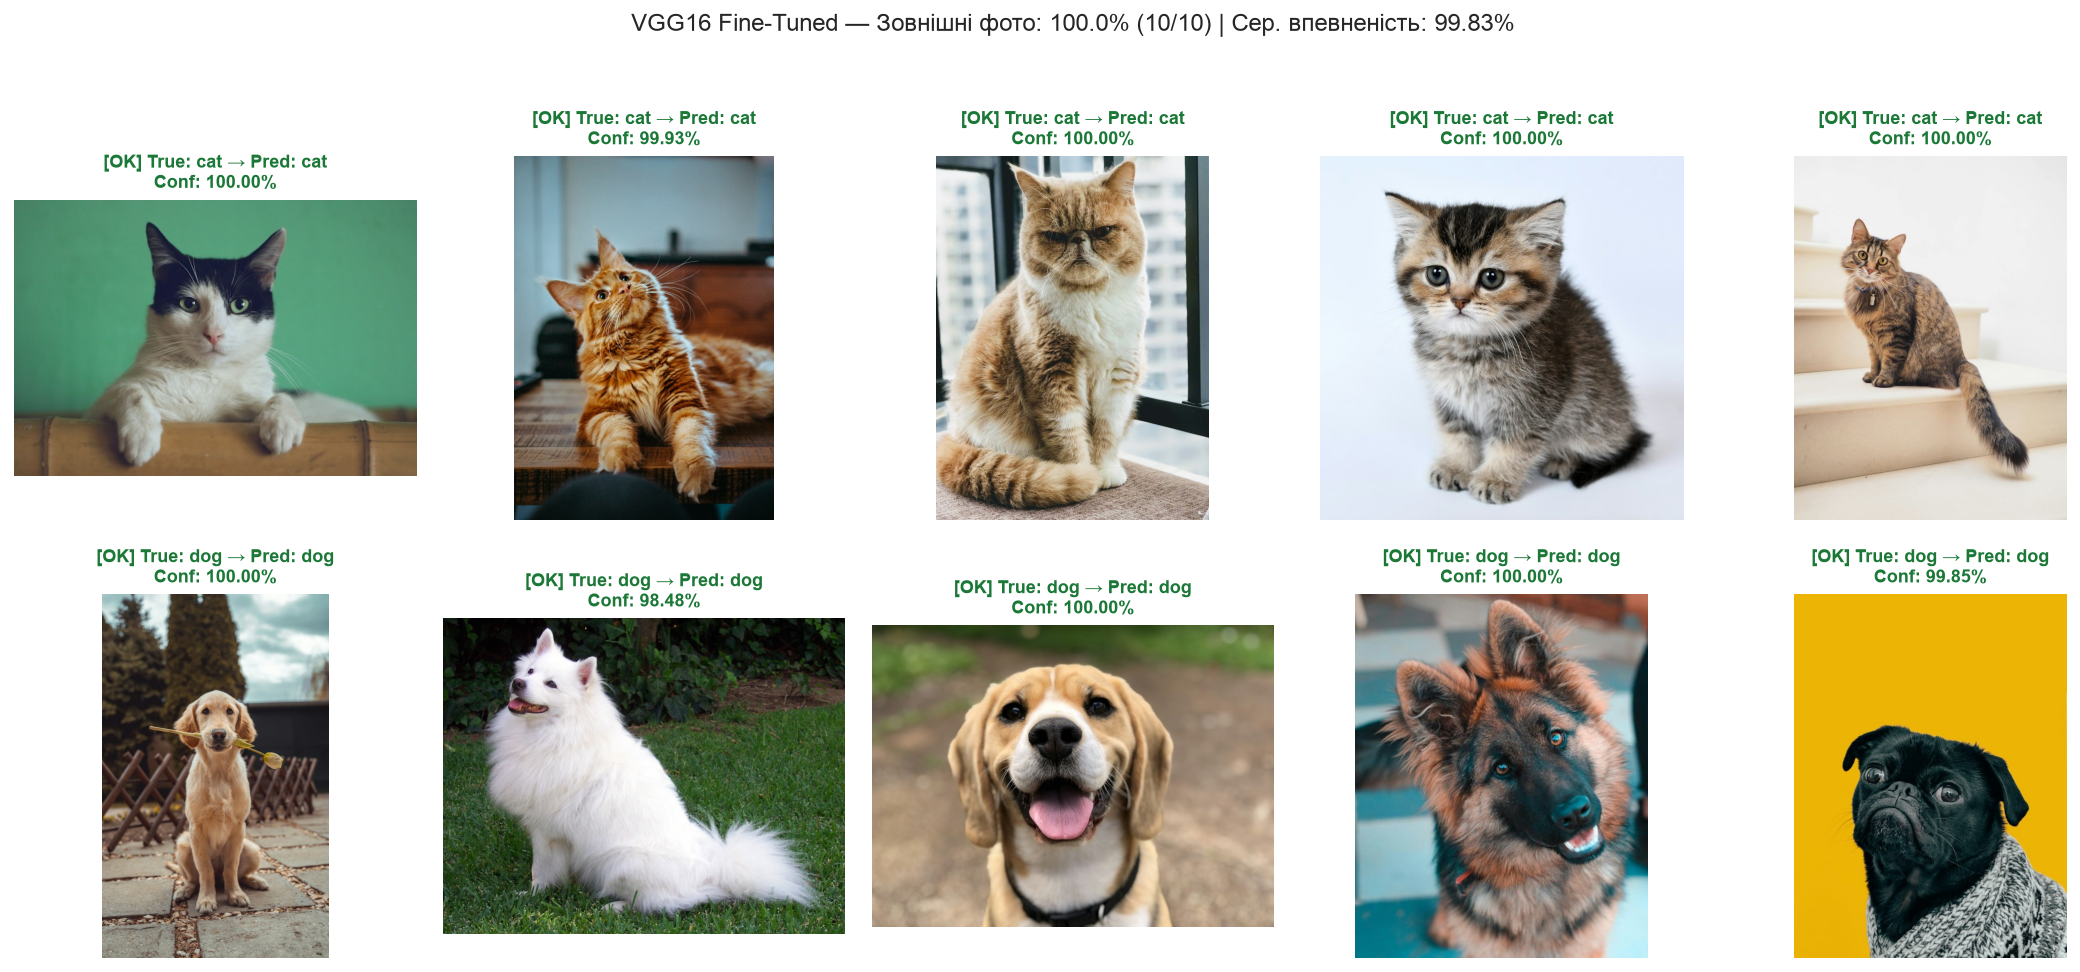

In [12]:
best_ex2_setting = str(df_ex2.sort_values("Best Val Loss").iloc[0]["Second Dense"])
best_d2_vgg = 0 if best_ex2_setting == "Без 2-го шару" else int(best_ex2_setting.replace("+Dense(", "").replace(")", ""))
best_do_vgg = 0.6 if best_d2_vgg > 0 else float(df_ex1b.sort_values("Best Val Loss").iloc[0]["Dropout Rate"])
print(
    f"Обрана конфігурація голови VGG16 за мінімумом Val Loss: "
    f"Dense=256, Dense2={best_d2_vgg}, Dropout={best_do_vgg}, lr=5e-6"
)

vgg_full_prefix = prepare_prefix_cache("vgg16", unfreeze_blocks=1, train_samples=6000, val_samples=None)
vgg_suffix_model, vgg_champ_rec = run_finetuning_experiment(
    model_key="vgg16",
    bottleneck_features=vgg_bottleneck,
    prefix_cache=vgg_full_prefix,
    unfreeze_blocks=1,
    dense_units=256,
    second_dense_units=best_d2_vgg,
    dropout_rate=best_do_vgg,
    optimizer_name="adam",
    learning_rate=5e-6,
    batch_size=50,
    warmup_epochs=20,
    finetune_epochs=8,
    warmup_on_full_train=True,
    experiment_name="vgg16_champion_finetuned",
    keep_model_in_memory=True,
)

plot_two_stage_curves(
    vgg_champ_rec,
    title_prefix="VGG16 Champion (Stage 1 Full Warm-up + Stage 2 Fine-Tuning)",
    save_name="01_vgg16_champion_curves.png",
)

vgg_final_summary = finalize_and_save_finetuned_model(
    model_key="vgg16",
    trained_suffix_model=vgg_suffix_model,
    experiment_record=vgg_champ_rec,
    prefix_cache=vgg_full_prefix,
)

plot_confusion_matrix(
    vgg_final_summary["test_metrics"]["confusion_matrix"],
    model_title="VGG16 Fine-Tuned (Test Split, 2502 фото)",
    save_name="01_vgg16_confusion_matrix.png",
)

df_vgg_ext = predict_external_images(MODELS_DIR / vgg_final_summary["save_filename"])
display(df_vgg_ext)
plot_external_predictions_grid(
    df_vgg_ext,
    model_title="VGG16 Fine-Tuned",
    save_name="01_vgg16_external_test.png",
)
